<a href="https://colab.research.google.com/github/nahushdeshmukh17/GenerativeAI-NN/blob/main/GEN_AI_202502110006_PR2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Practical No. 02: Text Classification using Embedding Layer and LSTM

**Name:** Nahush Pramod Deshmukh  
**PRN:** 202502110006  
**Topic:** Text Classification using Embedding Layer and LSTM

### Aim
To build a binary text classification model using an Embedding layer and LSTM network and evaluate the model using suitable classification metrics.

## Problem Statement

We will perform **binary sentiment classification** on IMDB movie reviews.

```text
Movie Review
     ↓
Integer Sequence
     ↓
Padding
     ↓
Embedding Layer
     ↓
LSTM
     ↓
Dense + Sigmoid
     ↓
Negative / Positive
```

### Architecture

- **Vocabulary size:** 10,000
- **Maximum sequence length:** 200
- **Embedding dimension:** 64
- **LSTM units:** 64
- **Dropout:** 0.2
- **Output:** 1 neuron with Sigmoid
- **Loss:** Binary Crossentropy
- **Optimizer:** Adam
- **Maximum epochs:** 10
- **Batch size:** 32
- **Early Stopping:** Yes

We use **10,000 reviews for the working dataset** to keep the practical reasonably fast. From these, 80% is used for training and 20% for validation. A separate **2,000-review test set** is kept for final evaluation.

### Cell 1 — Import libraries
Here we import the libraries needed for the dataset, LSTM model, graphs and evaluation metrics.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

### Cell 2 — Load the IMDB dataset
The IMDB dataset contains movie reviews with two labels: 0 for negative and 1 for positive. We keep the 10,000 most frequent words.

In [2]:
vocab_size = 10000

(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)

print("Original training samples:", len(x_train_full))
print("Original testing samples:", len(x_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Original training samples: 25000
Original testing samples: 25000


### Cell 3 — Select a smaller dataset
The complete IMDB training set is larger than needed for this practical, so we take 10,000 training reviews. We keep 2,000 reviews from the original test set for final testing.

In [3]:
x_train = x_train_full[:10000]
y_train = y_train_full[:10000]

x_test = x_test[:2000]
y_test = y_test[:2000]

print("Working training samples:", len(x_train))
print("Final test samples:", len(x_test))

Working training samples: 10000
Final test samples: 2000


### Cell 4 — Check the data
The reviews are already represented as integer sequences. We check one review and its label.

In [4]:
print("First review sequence:")
print(x_train[0][:20])

print("\nFirst review label:")
print(y_train[0])

print("\nLabel meaning: 0 = Negative, 1 = Positive")

First review sequence:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]

First review label:
1

Label meaning: 0 = Negative, 1 = Positive


### Cell 5 — Pad the sequences
Reviews have different lengths. We make every review 200 tokens long so that they can be given to the LSTM in batches.

In [5]:
max_length = 200

x_train = pad_sequences(
    x_train,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

Training shape: (10000, 200)
Test shape: (2000, 200)


### Cell 6 — Build the LSTM model
The Embedding layer converts word IDs into 64-dimensional vectors. The LSTM learns the sequence information. Dropout is added to reduce overfitting.

In [11]:
from tensorflow.keras.layers import Input

model = Sequential([
    Input(shape=(max_length,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64, dropout=0.2),
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

### Cell 7 — Compile the model
This is a binary classification problem, so Binary Crossentropy is used as the loss function. Adam is used to update the model weights.

In [12]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

### Cell 8 — Add Early Stopping
We allow the model to train for up to 10 epochs, but Early Stopping will stop training if validation loss does not improve for 2 consecutive epochs. The best weights are restored.

In [13]:
early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    mode='max',
    restore_best_weights=True
)

### Cell 9 — Train the model
We use 20% of the 10,000 working training reviews as validation data. The separate 2,000-review test set is not used during training.

In [14]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 41s 143ms/step - accuracy: 0.6672 - loss: 0.5837 - val_accuracy: 0.7930 - val_loss: 0.4354
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 36s 142ms/step - accuracy: 0.8616 - loss: 0.3349 - val_accuracy: 0.8480 - val_loss: 0.3685
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 44s 156ms/step - accuracy: 0.9221 - loss: 0.2137 - val_accuracy: 0.8380 - val_loss: 0.3880
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 154ms/step - accuracy: 0.9498 - loss: 0.1498 - val_accuracy: 0.8290 - val_loss: 0.4255
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 39s 146ms/step - accuracy: 0.9665 - loss: 0.1027 - val_accuracy: 0.8340 - val_loss: 0.4734


### Cell 10 — Plot training performance
These graphs show how training and validation accuracy and loss changed during training. They also help us notice overfitting.

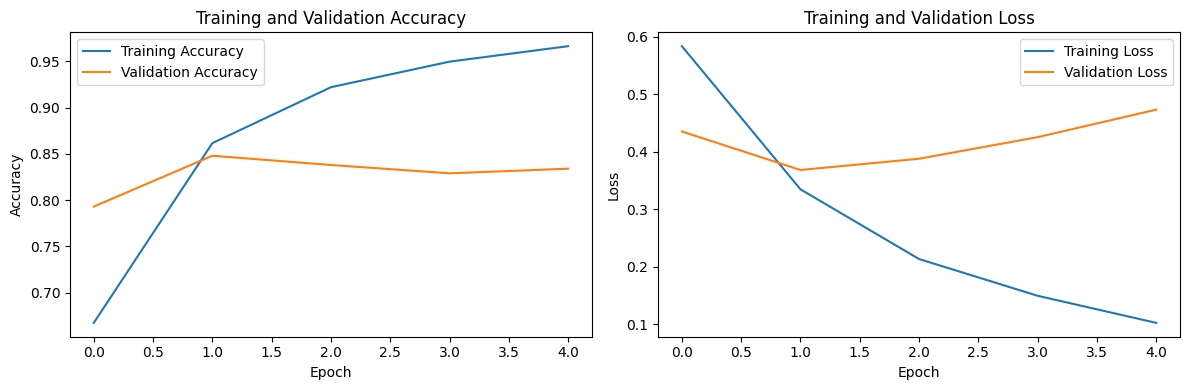

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

### Cell 11 — Final evaluation on test data
Now we evaluate the trained model on the separate test set that was not used for training or validation.

In [16]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss: 0.3842
Test Accuracy: 0.8390


### Cell 12 — Generate predictions
The model gives a probability between 0 and 1. We use 0.5 as the threshold to convert the probability into a negative or positive class.

In [17]:
y_prob = model.predict(x_test, verbose=0)

y_pred = (y_prob >= 0.5).astype(int).ravel()

print("Predictions generated successfully.")

Predictions generated successfully.


### Cell 13 — Calculate classification metrics
Here we calculate Accuracy, Precision, Recall and F1-score for the final test predictions.

In [18]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Accuracy : 0.8390
Precision: 0.8502
Recall   : 0.8038
F1-Score : 0.8263


### Cell 14 — Classification report
This gives the precision, recall and F1-score separately for negative and positive reviews.

In [19]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))

              precision    recall  f1-score   support

    Negative       0.83      0.87      0.85      1047
    Positive       0.85      0.80      0.83       953

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



### Cell 15 — Confusion matrix
The confusion matrix shows the number of correctly and incorrectly classified reviews for both classes.

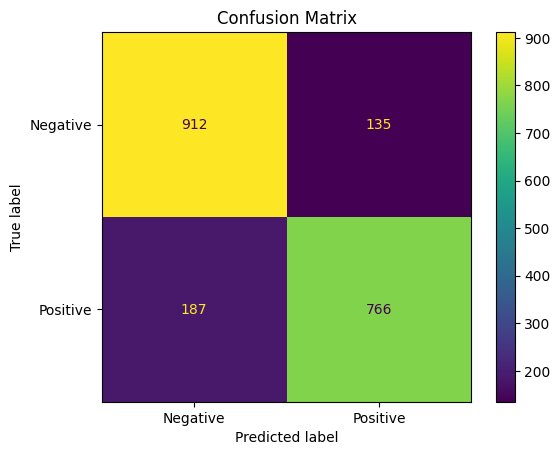

In [20]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

## Result and Conclusion

The binary text classification model was built using an **Embedding layer and LSTM network**.

The model classified IMDB movie reviews into **Negative** and **Positive** classes. The model was evaluated using **Accuracy, Precision, Recall, F1-Score and Confusion Matrix**.

The final numerical results should be reported from the outputs of the evaluation cells after running the notebook.